# AAI-003 | Customer Review Sentiment Analysis
**Complete project notebook | Invertis University, Bareilly | BCA AI | Semester V | Section A**

**Team Leader:** Virendra Pal  
**Mentor:** Sachin Kumar  
**Domain:** Natural Language Processing (NLP) / Binary Text Classification  
**Objective:** Classify English customer reviews as **Positive** or **Negative** using TF-IDF with Logistic Regression and Multinomial Naive Bayes.

> **Scope honesty:** The selected UCI dataset contains binary labels only. It does not provide a Neutral class, so this implementation is binary classification. This notebook downloads the public dataset directly. Run every cell from top to bottom to generate the real metrics, graphs, error review sheet, and saved model. Never copy placeholder metrics into the final report.


## 1. Project requirements and research design
- Use a labelled public review dataset.
- Inspect missing values, duplicates, label balance, and source distribution.
- Clean review text and document binary label definitions.
- Use review text only as model input; do not use customer rating or other target-derived fields.
- Split data into train, validation, and test partitions using stratification.
- Fit TF-IDF on training data only to avoid vocabulary leakage.
- Train Logistic Regression and Multinomial Naive Bayes.
- Select the model using validation macro-F1, then evaluate both models on the untouched test set.
- Report accuracy, macro precision, macro recall, macro-F1, class-wise precision/recall/F1, and confusion matrices.
- Inspect incorrect predictions using the original review wording.
- Demonstrate predictions on new sample reviews.
- Document dataset scope, limitations, and future work.


## 2. Install required packages

In [82]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Import libraries and set reproducibility

In [83]:
import os
import json
import zipfile
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
LABEL_ORDER = ["Negative", "Positive"]
OUTPUT_DIR = Path("outputs")
MODEL_DIR = Path("model")
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (9, 5)
print("Environment ready.")


Environment ready.


## 4. Download the UCI Sentiment Labelled Sentences dataset

In [84]:
DATA_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "00331/sentiment%20labelled%20sentences.zip"
)

ZIP_PATH = Path("sentiment_labelled_sentences.zip")
EXTRACT_DIR = Path("data/uci_sentiment")

# Create folder
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Download dataset
if not ZIP_PATH.exists():
    print("Downloading dataset from UCI...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

# Extract dataset
try:
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        if zf.testzip() is not None:
            raise zipfile.BadZipFile("Dataset ZIP is corrupted.")

        zf.extractall(EXTRACT_DIR)

    print("Dataset downloaded successfully!")
    print("ZIP Path:", ZIP_PATH.resolve())
    print("Extracted Path:", EXTRACT_DIR.resolve())

except zipfile.BadZipFile as e:
    print("Dataset ZIP error:", e)

Dataset downloaded successfully!
ZIP Path: C:\Users\pal30\sentiment_labelled_sentences.zip
Extracted Path: C:\Users\pal30\data\uci_sentiment


## 5. Load Amazon, IMDb, and Yelp review files
The expected files are tab-separated text files with review text and a binary label (`1=Positive`, `0=Negative`). The loader searches recursively so it works with the archive's nested folder structure. Rows that cannot be parsed as exactly two fields are skipped and the number of loaded rows is printed for transparency.


In [85]:
SOURCE_FILES = {
    "Amazon": "amazon_cells_labelled.txt",
    "IMDb": "imdb_labelled.txt",
    "Yelp": "yelp_labelled.txt",
}

records = []
load_audit = []

for source_name, file_name in SOURCE_FILES.items():
    matches = list(EXTRACT_DIR.rglob(file_name))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {file_name}. Check the UCI download/extraction."
        )
    file_path = matches[0]
    part = pd.read_csv(
        file_path,
        sep="\t",
        header=None,
        names=["review_text", "label"],
        engine="python",
        on_bad_lines="skip"
    )
    part["source"] = source_name
    part["label"] = pd.to_numeric(part["label"], errors="coerce")
    part = part[part["label"].isin([0, 1])].copy()
    load_audit.append({"Source": source_name, "Parsed rows": len(part)})
    records.append(part)

raw_df = pd.concat(records, ignore_index=True)
raw_df["sentiment"] = raw_df["label"].map({1: "Positive", 0: "Negative"})
display(pd.DataFrame(load_audit))
print("Total parsed rows:", len(raw_df))
display(raw_df.head())


,Source,Parsed rows
0,Amazon,1000
1,IMDb,743
2,Yelp,1000


Total parsed rows: 2743


,review_text,label,source,sentiment
0,So there is no way for me to plug it in here i...,0,Amazon,Negative
1,"Good case, Excellent value.",1,Amazon,Positive
2,Great for the jawbone.,1,Amazon,Positive
3,Tied to charger for conversations lasting more...,0,Amazon,Negative
4,The mic is great.,1,Amazon,Positive


## 6. Inspect dataset quality before cleaning

In [86]:
print("Shape:", raw_df.shape)
print("\\nMissing values:")
display(raw_df.isna().sum().to_frame("Missing values"))
print("\\nRaw label counts:")
display(raw_df["sentiment"].value_counts(dropna=False).to_frame("Count"))
print("\\nRows by source:")
display(raw_df["source"].value_counts().to_frame("Count"))
print("\\nExact duplicate review rows:", raw_df["review_text"].duplicated().sum())


Shape: (2743, 4)
\nMissing values:


,Missing values
review_text,0
label,0
source,0
sentiment,0


\nRaw label counts:


,Count
sentiment,
Positive,1384
Negative,1359


\nRows by source:


,Count
source,
Amazon,1000
Yelp,1000
IMDb,743


\nExact duplicate review rows: 17


## 7. Clean text and labels
Cleaning removes missing/empty text, normalizes leading/trailing whitespace, standardizes labels, and removes exact duplicate review text. We retain the original wording apart from whitespace trimming because aggressive cleaning (such as deleting negation or punctuation) can remove sentiment information. If the same exact sentence occurs in more than one source, only its first occurrence is retained to prevent identical text from crossing data splits.


In [87]:
df = raw_df.dropna(subset=["review_text", "sentiment"]).copy()
df["review_text"] = df["review_text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.title()
df = df[df["review_text"].ne("") & df["sentiment"].isin(LABEL_ORDER)].copy()

before_dedup = len(df)
df = df.drop_duplicates(subset=["review_text"], keep="first").reset_index(drop=True)
print("Rows before exact deduplication:", before_dedup)
print("Rows removed as exact duplicates:", before_dedup - len(df))
print("Final clean rows:", len(df))
display(df["sentiment"].value_counts().reindex(LABEL_ORDER).to_frame("Reviews"))


Rows before exact deduplication: 2743
Rows removed as exact duplicates: 18
Final clean rows: 2725


,Reviews
sentiment,
Negative,1351
Positive,1374


## 8. Check conflicting labels for identical review text

In [88]:
conflict_counts = raw_df.groupby("review_text")["sentiment"].nunique(dropna=True)
conflicts = conflict_counts[conflict_counts > 1]
print("Unique review texts with conflicting labels:", len(conflicts))
if len(conflicts):
    display(raw_df[raw_df["review_text"].isin(conflicts.index)].sort_values("review_text").head(20))
else:
    print("No conflicting labels found for identical review text.")


Unique review texts with conflicting labels: 0
No conflicting labels found for identical review text.


## 9. Visualize sentiment balance

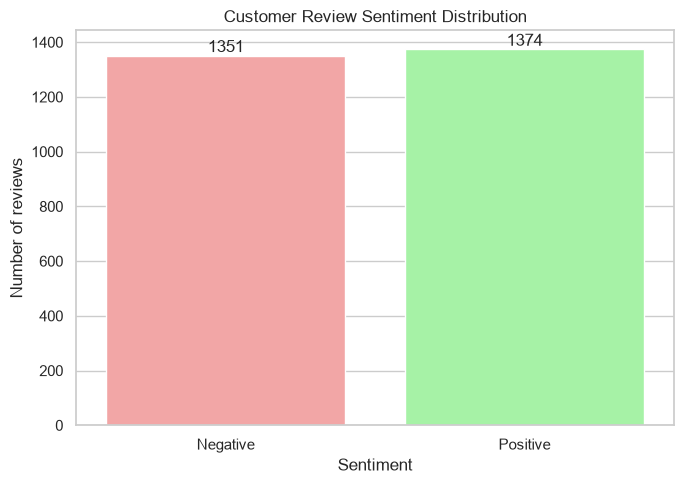

In [89]:
sentiment_counts = df["sentiment"].value_counts().reindex(
    LABEL_ORDER, fill_value=0
)
plt.figure(figsize=(7, 5))

# Light red for Negative, Light green for Positive
custom_palette = ["#ff9999", "#99ff99"]

ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    palette=custom_palette,
)
ax.set_title("Customer Review Sentiment Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of reviews")

for container in ax.containers:
  ax.bar_label(container)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "sentiment_distribution.png", dpi=200, bbox_inches="tight"
)
plt.show()

## 10. Explore source and review length

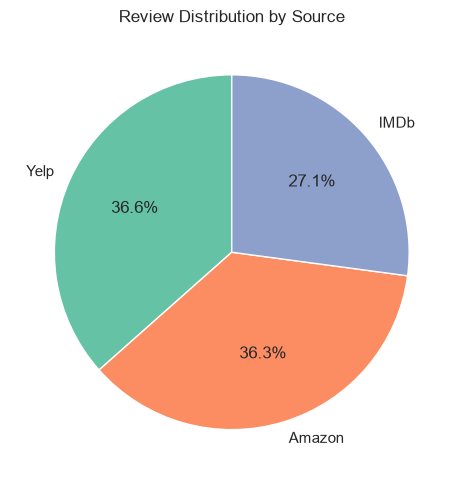

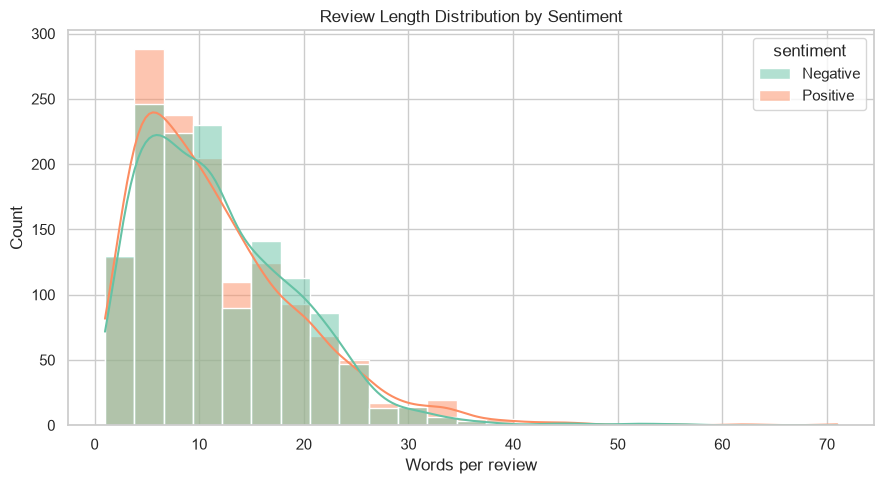

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,1351.0,11.82,7.42,1.0,6.0,11.0,16.0,56.0
Positive,1374.0,11.75,8.08,1.0,6.0,10.0,16.0,71.0


In [90]:
source_counts = df["source"].value_counts()
plt.figure(figsize=(7, 5))
plt.pie(source_counts.values, labels=source_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Review Distribution by Source")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "source_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

df["review_word_count"] = df["review_text"].str.split().str.len()
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="review_word_count", hue="sentiment", bins=25, kde=True)
plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Words per review")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "review_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()
display(df.groupby("sentiment")["review_word_count"].describe().round(2))


## 11. Define features and target
**Feature (`X`):** review text only.  
**Target (`y`):** Positive / Negative sentiment.  
The `source` field is used only for dataset inspection, not as a model feature. This avoids giving the classifier metadata unavailable in a normal review.


In [91]:
X = df["review_text"].astype(str)
y = df["sentiment"].astype(str)
assert set(y.unique()).issubset(set(LABEL_ORDER))
print("Total reviews:", len(X))
print("Target classes:", sorted(y.unique()))


Total reviews: 2725
Target classes: ['Negative', 'Positive']


## 12. Create stratified train / validation / test partitions (60/20/20)

In [92]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

split_summary = pd.DataFrame({
    "Partition": ["Train", "Validation", "Test"],
    "Rows": [len(X_train), len(X_valid), len(X_test)],
    "Share": [len(X_train)/len(X), len(X_valid)/len(X), len(X_test)/len(X)]
})
display(split_summary)
print("The test partition is held aside until model selection is complete.")


,Partition,Rows,Share
0,Train,1635,0.6
1,Validation,545,0.2
2,Test,545,0.2


The test partition is held aside until model selection is complete.


## 13. Convert text into TF-IDF features
The vectorizer is fitted on training text only. Validation and test data are transformed with the same fitted vocabulary. Unigrams and bigrams help represent individual terms and short phrases.


In [93]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_valid_tfidf = tfidf.transform(X_valid)
X_test_tfidf = tfidf.transform(X_test)
print("Train matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_valid_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)


Train matrix: (1635, 5000)
Validation matrix: (545, 5000)
Test matrix: (545, 5000)


## 14. Train Logistic Regression

In [94]:
lr_model = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
lr_model.fit(X_train_tfidf, y_train)
lr_valid_pred = lr_model.predict(X_valid_tfidf)
print("Logistic Regression training complete.")


Logistic Regression training complete.


## 15. Train Multinomial Naive Bayes

In [95]:
nb_model = MultinomialNB(alpha=0.5)
nb_model.fit(X_train_tfidf, y_train)
nb_valid_pred = nb_model.predict(X_valid_tfidf)
print("Multinomial Naive Bayes training complete.")


Multinomial Naive Bayes training complete.


## 16. Compare validation performance and select the final model

In [96]:
def calculate_metrics(model_name, actual, predicted):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro Precision": precision_score(actual, predicted, average="macro", zero_division=0),
        "Macro Recall": recall_score(actual, predicted, average="macro", zero_division=0),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0)
    }

validation_results = pd.DataFrame([
    calculate_metrics("Logistic Regression", y_valid, lr_valid_pred),
    calculate_metrics("Multinomial Naive Bayes", y_valid, nb_valid_pred)
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(validation_results.round(4))
best_model_name = validation_results.loc[0, "Model"]
best_model = lr_model if best_model_name == "Logistic Regression" else nb_model
print("Selected using validation Macro F1:", best_model_name)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7798,0.7802,0.7800,0.7798
1,Multinomial Naive Bayes,0.7651,0.7655,0.7649,0.7650


Selected using validation Macro F1: Logistic Regression


## 17. Final evaluation on the held-out test set
Both algorithms are evaluated on the same test partition. The test results are for final reporting and must not be used to change model settings after inspection.


In [97]:
lr_test_pred = lr_model.predict(X_test_tfidf)
nb_test_pred = nb_model.predict(X_test_tfidf)

test_results = pd.DataFrame([
    calculate_metrics("Logistic Regression", y_test, lr_test_pred),
    calculate_metrics("Multinomial Naive Bayes", y_test, nb_test_pred)
])
display(test_results.round(4))
test_results.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)
validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7853,0.7853,0.7854,0.7853
1,Multinomial Naive Bayes,0.7798,0.7804,0.7796,0.7796


## 18. Class-wise precision, recall, F1-score, and support

In [98]:
lr_report = pd.DataFrame(classification_report(
    y_test, lr_test_pred, labels=LABEL_ORDER, output_dict=True, zero_division=0
)).T
nb_report = pd.DataFrame(classification_report(
    y_test, nb_test_pred, labels=LABEL_ORDER, output_dict=True, zero_division=0
)).T

print("LOGISTIC REGRESSION — TEST CLASSIFICATION REPORT")
display(lr_report.round(4))
print("MULTINOMIAL NAIVE BAYES — TEST CLASSIFICATION REPORT")
display(nb_report.round(4))
lr_report.to_csv(OUTPUT_DIR / "logistic_regression_classification_report.csv")
nb_report.to_csv(OUTPUT_DIR / "naive_bayes_classification_report.csv")


LOGISTIC REGRESSION — TEST CLASSIFICATION REPORT


,precision,recall,f1-score,support
Negative,0.7802,0.7889,0.7845,270.0000
Positive,0.7904,0.7818,0.7861,275.0000
accuracy,0.7853,0.7853,0.7853,0.7853
macro avg,0.7853,0.7854,0.7853,545.0000
weighted avg,0.7854,0.7853,0.7853,545.0000


MULTINOMIAL NAIVE BAYES — TEST CLASSIFICATION REPORT


,precision,recall,f1-score,support
Negative,0.7907,0.7556,0.7727,270.0000
Positive,0.7700,0.8036,0.7865,275.0000
accuracy,0.7798,0.7798,0.7798,0.7798
macro avg,0.7804,0.7796,0.7796,545.0000
weighted avg,0.7803,0.7798,0.7797,545.0000


## 19. Confusion matrices

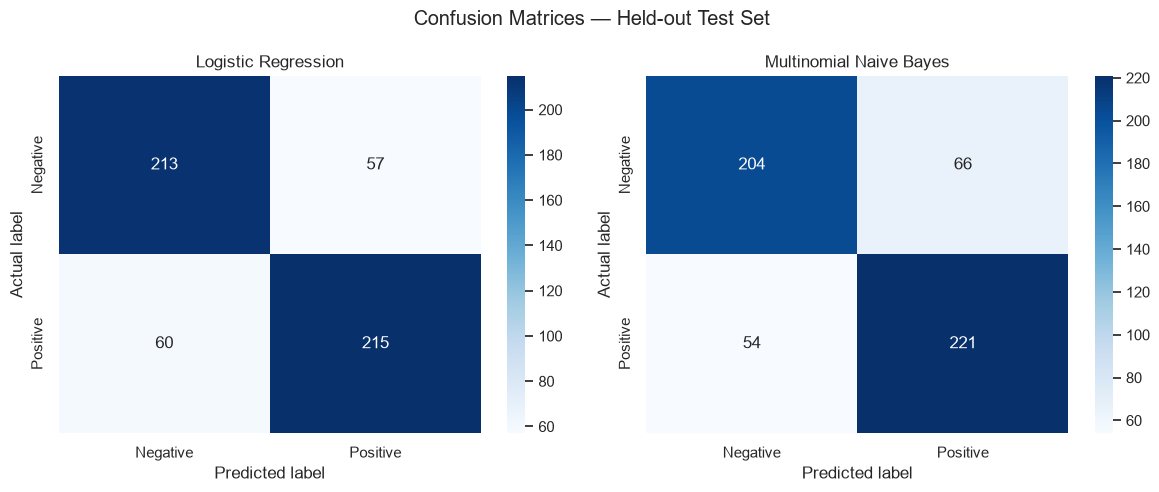

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model_name, predictions in [
    (axes[0], "Logistic Regression", lr_test_pred),
    (axes[1], "Multinomial Naive Bayes", nb_test_pred)
]:
    cm = confusion_matrix(y_test, predictions, labels=LABEL_ORDER)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER, ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.suptitle("Confusion Matrices — Held-out Test Set")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=220, bbox_inches="tight")
plt.show()


## 20. Compare test metrics visually

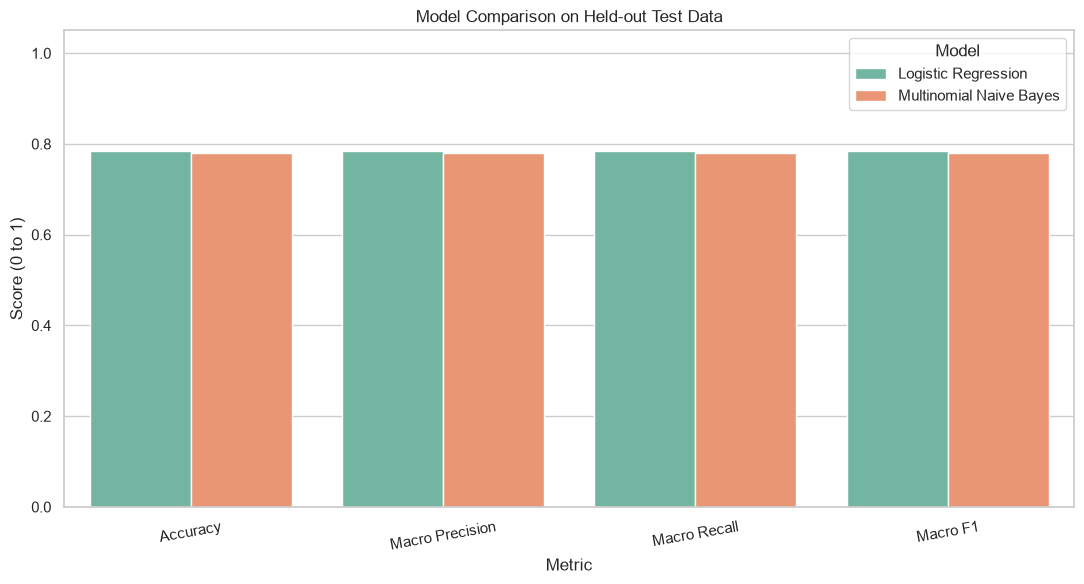

In [100]:
metric_columns = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
plot_data = test_results.melt(
    id_vars="Model", value_vars=metric_columns,
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(11, 6))
ax = sns.barplot(data=plot_data, x="Metric", y="Score", hue="Model")
ax.set_ylim(0, 1.05)
ax.set_title("Model Comparison on Held-out Test Data")
ax.set_ylabel("Score (0 to 1)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_metric_comparison.png", dpi=220, bbox_inches="tight")
plt.show()


## 21. Export predictions and prepare human error analysis

In [101]:
best_test_predictions = lr_test_pred if best_model_name == "Logistic Regression" else nb_test_pred
prediction_df = pd.DataFrame({
    "Original Review": X_test.reset_index(drop=True),
    "Actual Sentiment": y_test.reset_index(drop=True),
    "Predicted Sentiment": best_test_predictions
})
prediction_df["Correct"] = prediction_df["Actual Sentiment"] == prediction_df["Predicted Sentiment"]
errors = prediction_df.loc[~prediction_df["Correct"]].copy()
print("Test examples:", len(prediction_df))
print("Incorrect predictions:", len(errors))
display(prediction_df.head(12))
display(errors.head(15))
prediction_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)


Test examples: 545
Incorrect predictions: 117


,Original Review,Actual Sentiment,Predicted Sentiment,Correct
0,"There is, however, some pretty good acting (at...",Positive,Positive,True
1,Everything was perfect the night we were in.,Positive,Positive,True
2,Not good enough for the price.,Negative,Positive,False
3,"It was attached to a gas station, and that is ...",Negative,Positive,False
4,Also notable is John Bailey's fine crisp beaut...,Positive,Positive,True
5,The ambiance isn't much better.,Negative,Positive,False
6,"Simple, lightweight and great fit.",Positive,Positive,True
7,My wife had the Lobster Bisque soup which was ...,Negative,Positive,False
8,"In conclusion, I will not bother with this mov...",Negative,Negative,True
9,This place was such a nice surprise!,Positive,Positive,True


,Original Review,Actual Sentiment,Predicted Sentiment,Correct
2,Not good enough for the price.,Negative,Positive,False
3,"It was attached to a gas station, and that is ...",Negative,Positive,False
5,The ambiance isn't much better.,Negative,Positive,False
7,My wife had the Lobster Bisque soup which was ...,Negative,Positive,False
13,Having to humour him just to get by and get th...,Positive,Negative,False
31,"Predictable, but not a bad watch.",Positive,Negative,False
33,"He was extremely rude and really, there are so...",Negative,Positive,False
37,I bought this battery with a coupon from Amazo...,Positive,Negative,False
41,"This is a simple little phone to use, but the ...",Negative,Positive,False
48,"every thing on phone work perfectly, she like it.",Positive,Negative,False


## 22. Human review of at least five model errors
The next cell exports up to 20 incorrect predictions from the selected model. Open `outputs/error_review_to_complete.csv` in Excel and inspect the **original review wording** for at least five rows.

For each reviewed row, fill in both `Human review category` and `Human review note`. Choose a category only when the review supports it. Possible categories include: Negation, Mixed opinion / contrast, Ambiguous or very short wording, Sarcasm / irony (only when there is evidence), Context-dependent, Vocabulary / phrase issue, Possible dataset-label issue, or Other. Do not automatically call an error sarcasm, and do not invent an explanation.

Save the CSV in the same `outputs` folder, then run the following validation cell. It checks that at least five rows have both fields completed; it does not write human notes on your behalf.


In [102]:
# Build an editable error-analysis worksheet from the selected model's test errors.
import re

review_columns = [
    "Error ID", "Original Review", "Actual Sentiment", "Predicted Sentiment",
    "Possible clue to inspect (not a diagnosis)",
    "Human review category", "Human review note"
]

error_review_sheet = errors.head(20).copy().reset_index(drop=True)
error_review_sheet.insert(0, "Error ID", [f"ERR-{i:03d}" for i in range(1, len(error_review_sheet) + 1)])

# These are prompts for closer reading only; they are not automatic explanations.
def suggest_text_clue(review):
    text = str(review)
    clues = []
    if re.search(r"\b(not|no|never|n't|hardly|barely)\b", text, flags=re.IGNORECASE):
        clues.append("Check negation or scope")
    if re.search(r"\b(but|however|although|though|yet)\b", text, flags=re.IGNORECASE):
        clues.append("Check mixed opinion / contrast")
    if len(text.split()) <= 5:
        clues.append("Very short review; context may be missing")
    if re.search(r"[!?]{2,}|\b[A-Z]{3,}\b", text):
        clues.append("Check emphasis or punctuation in context")
    return "; ".join(clues) if clues else "Read wording and context; no obvious clue detected"

if not error_review_sheet.empty:
    error_review_sheet["Possible clue to inspect (not a diagnosis)"] = error_review_sheet["Original Review"].apply(suggest_text_clue)
else:
    error_review_sheet["Possible clue to inspect (not a diagnosis)"] = pd.Series(dtype="object")

error_review_sheet["Human review category"] = ""
error_review_sheet["Human review note"] = ""
error_review_sheet = error_review_sheet[review_columns]

review_file = OUTPUT_DIR / "error_review_to_complete.csv"
error_review_sheet.to_csv(review_file, index=False)

print(f"Incorrect predictions available for review: {len(error_review_sheet)}")
print("Review worksheet saved to:", review_file.resolve())
if len(error_review_sheet) < 5:
    print("Note: Fewer than five test errors were found. Review all available errors and report the actual count; do not create fake errors.")
else:
    print("Action: Complete at least five rows in Excel, save the CSV, then run the validation cell below.")
display(error_review_sheet.head(20))


Incorrect predictions available for review: 20
Review worksheet saved to: C:\Users\pal30\outputs\error_review_to_complete.csv
Action: Complete at least five rows in Excel, save the CSV, then run the validation cell below.


,Error ID,Original Review,Actual Sentiment,Predicted Sentiment,Possible clue to inspect (not a diagnosis),Human review category,Human review note
0,ERR-001,Not good enough for the price.,Negative,Positive,Check negation or scope,,
1,ERR-002,"It was attached to a gas station, and that is ...",Negative,Positive,Read wording and context; no obvious clue dete...,,
2,ERR-003,The ambiance isn't much better.,Negative,Positive,Very short review; context may be missing,,
3,ERR-004,My wife had the Lobster Bisque soup which was ...,Negative,Positive,Read wording and context; no obvious clue dete...,,
4,ERR-005,Having to humour him just to get by and get th...,Positive,Negative,Read wording and context; no obvious clue dete...,,
5,ERR-006,"Predictable, but not a bad watch.",Positive,Negative,Check negation or scope; Check mixed opinion /...,,
6,ERR-007,"He was extremely rude and really, there are so...",Negative,Positive,Read wording and context; no obvious clue dete...,,
7,ERR-008,I bought this battery with a coupon from Amazo...,Positive,Negative,Read wording and context; no obvious clue dete...,,
8,ERR-009,"This is a simple little phone to use, but the ...",Negative,Positive,Check mixed opinion / contrast,,
9,ERR-010,"every thing on phone work perfectly, she like it.",Positive,Negative,Read wording and context; no obvious clue dete...,,


In [103]:
# Validate the human error-analysis notes after editing the CSV in Excel.
review_file = OUTPUT_DIR / "error_review_to_complete.csv"

if not review_file.exists():
    print("Review worksheet not found. Run the error-review worksheet cell first.")
else:
    reviewed_df = pd.read_csv(review_file).fillna("")
    required_review_fields = ["Human review category", "Human review note"]
    missing_fields = [col for col in required_review_fields if col not in reviewed_df.columns]

    if missing_fields:
        print("Missing columns in review worksheet:", missing_fields)
    else:
        completed = (
            reviewed_df["Human review category"].astype(str).str.strip().ne("") &
            reviewed_df["Human review note"].astype(str).str.strip().ne("")
        )
        completed_count = int(completed.sum())
        print(f"Completed human error reviews: {completed_count}")
        print("Minimum required: 5")
        if completed_count >= 5:
            print("SUCCESS: At least five errors have human review categories and evidence-based notes.")
        else:
            print(f"PENDING: Complete {5 - completed_count} more row(s), then save the CSV and rerun this cell.")
        display(reviewed_df.loc[completed, ["Error ID", "Actual Sentiment", "Predicted Sentiment", "Human review category", "Human review note"]])


Completed human error reviews: 0
Minimum required: 5
PENDING: Complete 5 more row(s), then save the CSV and rerun this cell.


,Error ID,Actual Sentiment,Predicted Sentiment,Human review category,Human review note


## 23. Predict sentiment for new customer reviews

In [104]:
def predict_sentiment(review_text):
    if not isinstance(review_text, str) or not review_text.strip():
        raise ValueError("Please enter a non-empty review.")
    vector = tfidf.transform([review_text.strip()])
    predicted_label = best_model.predict(vector)[0]
    probabilities = best_model.predict_proba(vector)[0]
    class_probabilities = dict(zip(best_model.classes_, probabilities))
    return {
        "Review": review_text,
        "Predicted sentiment": predicted_label,
        "Estimated confidence (%)": round(float(max(probabilities) * 100), 2),
        "Negative probability (%)": round(float(class_probabilities.get("Negative", 0) * 100), 2),
        "Positive probability (%)": round(float(class_probabilities.get("Positive", 0) * 100), 2)
    }

sample_reviews = [
    "This product is excellent and works exactly as expected.",
    "The service was terrible and I will not return.",
    "The food was tasty but the waiting time was too long.",
    "I did not like the quality of this product."
]
sample_predictions = pd.DataFrame([predict_sentiment(text) for text in sample_reviews])
display(sample_predictions)
sample_predictions.to_csv(OUTPUT_DIR / "sample_predictions.csv", index=False)


,Review,Predicted sentiment,Estimated confidence (%),Negative probability (%),Positive probability (%)
0,This product is excellent and works exactly as...,Positive,78.89,21.11,78.89
1,The service was terrible and I will not return.,Negative,85.99,85.99,14.01
2,The food was tasty but the waiting time was to...,Negative,66.17,66.17,33.83
3,I did not like the quality of this product.,Positive,54.42,45.58,54.42


## 24. Save the trained model pipeline

In [105]:
pipeline_bundle = {
    "model": best_model,
    "tfidf": tfidf,
    "model_name": best_model_name,
    "labels": LABEL_ORDER,
    "random_state": RANDOM_STATE
}
joblib.dump(pipeline_bundle, MODEL_DIR / "sentiment_model_pipeline.joblib")
print("Saved model:", (MODEL_DIR / "sentiment_model_pipeline.joblib").resolve())


Saved model: C:\Users\pal30\model\sentiment_model_pipeline.joblib


## 25. Save cleaned dataset and run summary

In [106]:
import json
from pathlib import Path

# Create output folder if it does not exist
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
df.to_csv(OUTPUT_DIR / "cleaned_customer_reviews.csv", index=False)

# Create run summary
run_summary = {
    "Project": "AAI-003 Customer Review Sentiment Analysis",
    "Dataset": "UCI Sentiment Labelled Sentences",
    "Cleaned unique reviews": int(len(df)),
    "Negative reviews": int((df["sentiment"] == "Negative").sum()),
    "Positive reviews": int((df["sentiment"] == "Positive").sum()),
    "Train rows": int(len(X_train)),
    "Validation rows": int(len(X_valid)),
    "Test rows": int(len(X_test)),
    "Selected model (validation Macro F1)": str(best_model_name),
    "Incorrect selected-model test predictions": int(
        (best_test_predictions != y_test.to_numpy()).sum()
    ),
    "Test model metrics": test_results.round(4).to_dict(orient="records")
}

# Save JSON summary
summary_path = OUTPUT_DIR / "run_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2, ensure_ascii=False)

# Display summary
print(json.dumps(run_summary, indent=2, ensure_ascii=False))

print("\nFiles saved successfully!")
print("CSV:", OUTPUT_DIR / "cleaned_customer_reviews.csv")
print("JSON:", summary_path)

{
  "Project": "AAI-003 Customer Review Sentiment Analysis",
  "Dataset": "UCI Sentiment Labelled Sentences",
  "Cleaned unique reviews": 2725,
  "Negative reviews": 1351,
  "Positive reviews": 1374,
  "Train rows": 1635,
  "Validation rows": 545,
  "Test rows": 545,
  "Selected model (validation Macro F1)": "Logistic Regression",
  "Incorrect selected-model test predictions": 117,
  "Test model metrics": [
    {
      "Model": "Logistic Regression",
      "Accuracy": 0.7853,
      "Macro Precision": 0.7853,
      "Macro Recall": 0.7854,
      "Macro F1": 0.7853
    },
    {
      "Model": "Multinomial Naive Bayes",
      "Accuracy": 0.7798,
      "Macro Precision": 0.7804,
      "Macro Recall": 0.7796,
      "Macro F1": 0.7796
    }
  ]
}

Files saved successfully!
CSV: outputs\cleaned_customer_reviews.csv
JSON: outputs\run_summary.json


## 26. Limitations, ethical use, and future scope
**Limitations**
- The dataset has only Positive and Negative labels; neutral or mixed sentiment is not available.
- The dataset is English-language and relatively small compared with modern review platforms.
- Sarcasm, irony, negation, mixed opinions, spelling variation, slang, and context may cause errors.
- TF-IDF represents word patterns; it does not deeply understand meaning or context.
- Amazon, IMDb, and Yelp examples may not represent every product, service, region, or customer group.
- Confidence is a model probability estimate, not a guarantee of correctness.

**Responsible use**
- Treat predictions as decision support, not as the final judgment about a customer.
- Allow a human reviewer to correct unclear or high-impact predictions.
- Do not feed personal or sensitive customer information into an unapproved system.

**Future scope**
- Add a properly labelled Neutral class and evaluate three-class classification.
- Expand the dataset with fresh, representative domains and languages.
- Compare linear SVM and transformer-based models under the same held-out evaluation.
- Build a small user interface and collect human feedback for continuous review.


## 27. Final project completion checklist
- [ ] Run all notebook cells from top to bottom without errors.
- [ ] Confirm dataset download and record the observed parsed/cleaned row counts.
- [ ] Save all graphs and CSV outputs from the `outputs/` folder.
- [ ] Manually inspect at least five incorrect predictions and complete the error notes.
- [ ] Copy actual test metrics into the report and presentation.
- [ ] Test the saved model with at least five new review examples.
- [ ] Include the UCI dataset citation and comply with its licence/attribution terms.
- [ ] Team leader checks that notebook, report, slides, and screenshots agree.
